In [41]:
#Importe de librerias necesarias 
import numpy as np
import pandas as pd
from geopy.geocoders import Nominatim   # OpenStreetMap, 1 consulta/seg
import time
import matplotlib.pyplot as plt
import requests
import time
from typing import Union, List, Optional

In [ ]:
def distancias_cap_provincias(
    ciudades: List[str]
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Calcula la matriz de distancias geodésicas (en línea recta) entre una lista
    de capitales provinciales usando la fórmula del semiverseno (Haversine).

    Parámetros (Entradas):
    -----------------------
    ciudades : List[str]
        Lista con los nombres de las ciudades/capitales a geolocalizar.

    Retorna (Salidas):
    ------------------
    Tuple[np.ndarray, np.ndarray]
        - D_recta (np.ndarray): Matriz simétrica (N x N) con las distancias
          en kilómetros entre cada par de ciudades.
        - coords_grados (np.ndarray): Matriz (N x 2) con las coordenadas
          en grados decimales [latitud, longitud] de cada ciudad.
    """
    # Inicialización del geocodificador con timeout preventivo de 10 segundos
    geo = Nominatim(user_agent="tp-tsp-espana", timeout=10)
    coords_lista = []

    for c in ciudades:
        loc = geo.geocode(f"{c}, España")
        if loc is None:
            raise ValueError(f"No se pudieron encontrar las coordenadas para: {c}")
        
        coords_lista.append((loc.latitude, loc.longitude))
        time.sleep(1.1)  # Respetar la política de uso de OSM (máx. 1 req/seg)
    
    # Coordenadas en grados (N x 2)
    coords_grados = np.array(coords_lista)

    # Conversión a radianes para cálculo trigonométrico
    coords_rads = np.radians(coords_grados)
    lat, lon = coords_rads[:, 0][:, None], coords_rads[:, 1][:, None]

    # Fórmula del semiverseno (Haversine)
    a = (np.sin((lat - lat.T) / 2) ** 2 + 
         np.cos(lat) * np.cos(lat.T) * np.sin((lon - lon.T) / 2) ** 2)
    
    # Matriz final de distancias en kilómetros (Radio de la Tierra: 6371.0 km)
    D_recta = 2 * 6371.0 * np.arcsin(np.sqrt(a))

    return D_recta, coords_grados


In [32]:
#Ejecucion de la funcion 
ciudades_espana = [
    "A Coruña", "Albacete", "Alicante", "Almería", "Ávila", "Badajoz",
    "Barcelona", "Bilbao", "Burgos", "Cáceres", "Cádiz", "Castellón de la Plana",
    "Ciudad Real", "Córdoba", "Cuenca", "Girona", "Granada", "Guadalajara",
    "Huelva", "Huesca", "Jaén", "León", "Lleida", "Logroño", "Lugo", "Madrid",
    "Málaga", "Murcia", "Ourense", "Oviedo", "Palencia", "Pamplona",
    "Pontevedra", "Salamanca", "San Sebastián", "Santander", "Segovia",
    "Sevilla", "Soria", "Tarragona", "Teruel", "Toledo", "Valencia",
    "Valladolid", "Vitoria-Gasteiz", "Zamora", "Zaragoza"
]

Matriz_distancias_rectas, lat_long_provincias = distancias_cap_provincias(ciudades_espana)


In [34]:
print(Matriz_distancias_rectas)

[[  0.         731.22753738 867.51826029 ... 470.18882255 274.00721896
  641.62795305]
 [731.22753738   0.         139.09232476 ... 434.01398115 457.57415456
  310.35942523]
 [867.51826029 139.09232476   0.         ... 533.63180812 594.63956657
  374.0034816 ]
 ...
 [470.18882255 434.01398115 533.63180812 ...   0.         299.39826719
  193.31457597]
 [274.00721896 457.57415456 594.63956657 ... 299.39826719   0.
  417.79885401]
 [641.62795305 310.35942523 374.0034816  ... 193.31457597 417.79885401
    0.        ]]


In [37]:
def graficar_y_exportar_ciudades(
    coordenadas: Union[np.ndarray, List],
    nombres_ciudades: Optional[List[str]] = None,
    nombre_archivo: str = "mapa_ciudades_tsp.png",
    dpi: int = 300
) -> str:
    """
    Grafica la ubicación geográfica de las ciudades (puntos del TSP) y
    exporta el gráfico como una imagen en disco.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    nombres_ciudades : Optional[List[str]], opcional
        Lista con los nombres de las ciudades para etiquetarlas. Si no se
        proporciona, se etiquetan con su índice numérico (0, 1, 2, ...).
    nombre_archivo : str, opcional
        Nombre o ruta del archivo de imagen a generar (por defecto "mapa_ciudades_tsp.png").
    dpi : int, opcional
        Resolución de la imagen exportada en puntos por pulgada (por defecto 300 DPI).

    Retorna (Salida):
    ------------------
    str
        Ruta o nombre del archivo de imagen exportado exitosamente.
    """
    coords_arr = np.array(coordenadas)

    # Asegurar que las coordenadas estén en grados decimales
    if np.max(coords_arr) < 7:  # Si los valores son pequeños, están en radianes
        coords_deg = np.degrees(coords_arr)
    else:
        coords_deg = coords_arr

    lats = coords_deg[:, 0]
    lons = coords_deg[:, 1]

    # Crear figura
    fig, ax = plt.subplots(figsize=(10, 7))

    # Graficar puntos: Longitud en X (horizontal), Latitud en Y (vertical)
    ax.scatter(lons, lats, c='crimson', s=60, edgecolors='black', zorder=2)

    # Etiquetar cada punto (con nombre si existe, o con índice numérico)
    for i, (lat, lon) in enumerate(zip(lats, lons)):
        etiqueta = nombres_ciudades[i] if nombres_ciudades is not None else str(i)
        ax.annotate(etiqueta, (lon, lat), textcoords="offset points", 
                    xytext=(5, 5), fontsize=8, alpha=0.85)

    ax.set_title("Ubicación de las Ciudades (Puntos del TSP)", fontsize=13, pad=12)
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.axis('equal')  # Mantener proporciones geográficas reales

    # Exportar imagen a disco
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=dpi, bbox_inches='tight')
    plt.show()

    print(f"Imagen exportada con éxito en: {nombre_archivo}")
    return nombre_archivo


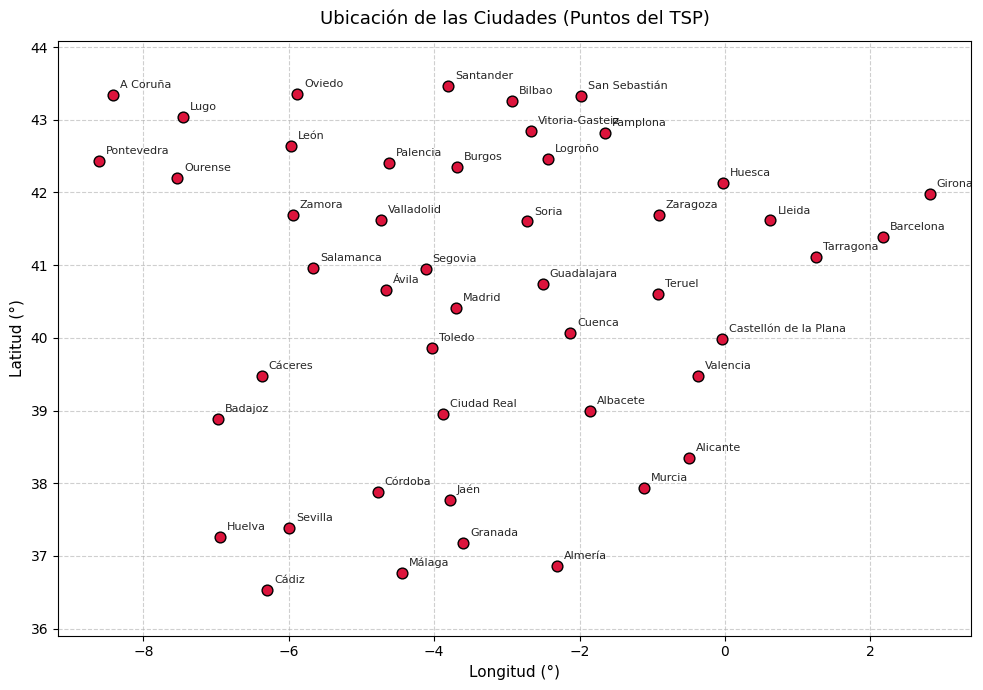

Imagen exportada con éxito en: mapa_espana_provincias.png


In [38]:
ruta_imagen = graficar_y_exportar_ciudades(
    coordenadas=lat_long_provincias,
    nombres_ciudades=ciudades_espana,
    nombre_archivo="mapa_espana_provincias.png"
)


In [42]:
def calcular_distancias_carretera_osrm(
    coordenadas: Union[np.ndarray, List],
    nombres_ciudades: Optional[List[str]] = None,
    guardar_csv: Optional[str] = "matriz_distancias_carretera.csv",
    timeout: int = 30
) -> np.ndarray:
    """
    Calcula la matriz de distancias reales por carretera (en kilómetros) usando
    la API de OSRM y exporta el resultado en formato CSV.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    nombres_ciudades : Optional[List[str]], opcional
        Lista con los nombres de las ciudades para los encabezados de filas
        y columnas del CSV.
    guardar_csv : Optional[str], opcional
        Nombre del archivo CSV donde se guardará la matriz (por defecto "matriz_distancias_carretera.csv").
        Si es None, no se guarda en disco.
    timeout : int, opcional
        Tiempo máximo de espera en segundos para la consulta (por defecto 30).

    Retorna (Salida):
    ------------------
    np.ndarray
        Matriz simétrica (N x N) con las distancias de conducción por carretera
        en kilómetros.
    """
    coords_arr = np.array(coordenadas)

    # 1. Asegurar coordenadas en grados decimales
    if np.max(coords_arr) < 7:
        coords_grados = np.degrees(coords_arr)
    else:
        coords_grados = coords_arr

    # 2. Formatear para OSRM ("lon,lat")
    coords_str = ";".join([f"{lon:.6f},{lat:.6f}" for lat, lon in coords_grados])
    url = f"http://router.project-osrm.org/table/v1/driving/{coords_str}?annotations=distance"

    # 3. Petición a la API
    try:
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        data = response.json()
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"Error de conexión al consultar OSRM: {e}")

    # 4. Validar respuesta
    if data.get("code") != "Ok":
        mensaje = data.get("message", "Error desconocido de OSRM")
        raise RuntimeError(f"La API de OSRM devolvió un error: {mensaje}")

    # 5. Convertir metros a kilómetros
    D_carretera = np.array(data["distances"]) / 1000.0

    # 6. Guardar en formato CSV con Pandas
    if guardar_csv:
        encabezados = nombres_ciudades if nombres_ciudades is not None else range(len(D_carretera))
        df_carretera = pd.DataFrame(
            D_carretera.round(2), 
            index=encabezados, 
            columns=encabezados
        )
        # encoding="utf-8-sig" para que las tildes se vean bien en Excel
        df_carretera.to_csv(guardar_csv, encoding="utf-8-sig")
        print(f"Matriz guardada en CSV: {guardar_csv}")

    # Estadísticas informativas
    print("¡Éxito! Matriz por carretera obtenida correctamente.")
    print("Dimensiones:", D_carretera.shape)
    print("Distancia mínima (distinta de 0):", round(D_carretera[D_carretera > 0].min(), 2), "km")
    print("Distancia máxima:", round(D_carretera.max(), 2), "km")

    return D_carretera




In [43]:
Matriz_distancias_carretera = calcular_distancias_carretera_osrm(
    coordenadas=lat_long_provincias,
    nombres_ciudades=ciudades_espana,
    guardar_csv="matriz_distancias_carretera.csv"
)

Matriz guardada en CSV: matriz_distancias_carretera.csv
¡Éxito! Matriz por carretera obtenida correctamente.
Dimensiones: (47, 47)
Distancia mínima (distinta de 0): 62.94 km
Distancia máxima: 1212.48 km


In [49]:
print(Matriz_distancias_carretera)

[[   0.      847.8935 1011.4495 ...  602.6458  396.6254  783.4124]
 [ 846.3341    0.      167.5808 ...  603.5406  551.8872  411.587 ]
 [1010.5418  167.5469    0.     ...  735.3059  716.0948  482.6427]
 ...
 [ 591.0671  598.9563  728.0143 ...    0.      376.4057  262.0168]
 [ 396.7653  553.0954  716.6515 ...  383.0094    0.      563.7759]
 [ 776.5068  401.9096  481.2661 ...  267.2516  561.8454    0.    ]]


In [47]:
def graficar_y_exportar_red_carreteras(
    coordenadas: Union[np.ndarray, List],
    matriz_distancias: np.ndarray,
    nombres_ciudades: List[str],
    k_vecinos: int = 4,
    nombre_archivo: str = "red_vial_espana_tsp.png",
    dpi: int = 300
) -> str:
    """
    Grafica la red vial de las ciudades conectando cada una con sus vecinos
    más cercanos por carretera, colorea los nodos según su accesibilidad media
    y exporta el gráfico como imagen en disco.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    matriz_distancias : np.ndarray
        Matriz simétrica (N x N) con las distancias de conducción por carretera (en km).
    nombres_ciudades : List[str]
        Lista con los nombres de las ciudades correspondientes a cada índice.
    k_vecinos : int, opcional
        Cantidad de ciudades vecinas más cercanas a conectar con cada punto (por defecto 4).
    nombre_archivo : str, opcional
        Nombre o ruta del archivo de imagen a generar (por defecto "red_vial_espana_tsp.png").
    dpi : int, opcional
        Resolución de la imagen exportada en puntos por pulgada (por defecto 300 DPI).

    Retorna (Salida):
    ------------------
    str
        Ruta o nombre del archivo de imagen exportado exitosamente.
    """
    coords_arr = np.array(coordenadas)

    # 1. Asegurar coordenadas en grados decimales
    if np.max(coords_arr) < 7:
        coords_deg = np.degrees(coords_arr)
    else:
        coords_deg = coords_arr

    lats = coords_deg[:, 0]
    lons = coords_deg[:, 1]

    # Distancia promedio de cada ciudad al resto (para el mapa de calor)
    dist_promedio = np.mean(matriz_distancias, axis=1)

    # 2. Configurar la figura
    fig, ax = plt.subplots(figsize=(14, 10))

    # 3. Trazar conexiones a los k vecinos más cercanos por carretera
    lineas_dibujadas = set()
    for i in range(len(coords_deg)):
        # Índices ordenados por menor distancia (se excluye el índice 0 que es la misma ciudad)
        vecinos = np.argsort(matriz_distancias[i])[1 : k_vecinos + 1]
        for j in vecinos:
            par = tuple(sorted((i, j)))
            if par not in lineas_dibujadas:
                lineas_dibujadas.add(par)
                # Línea discontinua
                ax.plot([lons[i], lons[j]], [lats[i], lats[j]], 
                        color='gray', linestyle='--', linewidth=1.0, alpha=0.6, zorder=1)
                
                # Texto con la distancia en kilómetros en el punto medio
                mid_lon = (lons[i] + lons[j]) / 2
                mid_lat = (lats[i] + lats[j]) / 2
                dist_km = int(matriz_distancias[i, j])
                ax.text(mid_lon, mid_lat, f"{dist_km} km", 
                        fontsize=7, color='darkblue', alpha=0.8, ha='center',
                        bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))

    # 4. Graficar nodos/ciudades
    scatter = ax.scatter(lons, lats, c=dist_promedio, cmap='plasma', s=120, 
                         edgecolors='black', linewidth=1.2, zorder=3)

    # 5. Etiquetar cada ciudad con su índice y nombre
    for i, (nombre, lat, lon) in enumerate(zip(nombres_ciudades, lats, lons)):
        ax.annotate(f"{i}. {nombre}", (lon, lat), 
                    textcoords="offset points", xytext=(4, 4), 
                    fontsize=8, fontweight='semibold', color='black', zorder=4)

    # 6. Barra de color y títulos
    cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.03, pad=0.02)
    cbar.set_label('Distancia media al resto de ciudades por carretera (km)', fontsize=10)

    ax.set_title("Red Vial de España - Puntos del TSP con Distancias Reales por Carretera (OSRM)", fontsize=13, pad=15)
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.axis('equal')  # Mantener proporciones geográficas reales

    # 7. Guardar y mostrar
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=dpi, bbox_inches='tight')
    plt.show()

    print(f"Imagen exportada con éxito en: {nombre_archivo}")
    return nombre_archivo


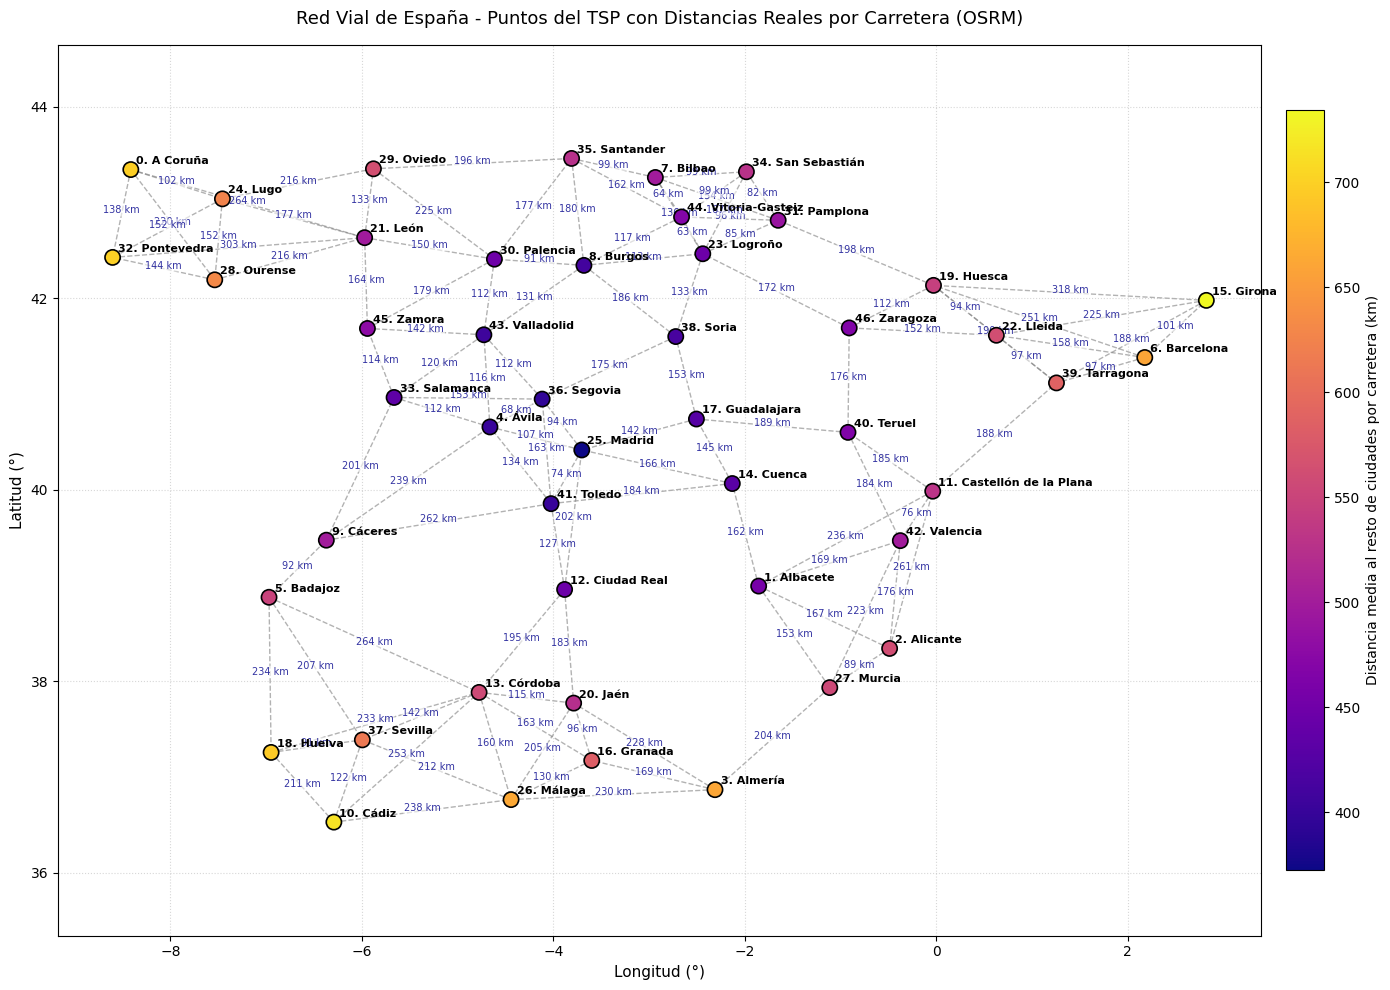

Imagen exportada con éxito en: red_vial_espana_tsp.png


In [48]:
ruta_red_vial = graficar_y_exportar_red_carreteras(
    coordenadas=lat_long_provincias,
    matriz_distancias=Matriz_distancias_carretera,
    nombres_ciudades=ciudades_espana,
    k_vecinos=4,
    nombre_archivo="red_vial_espana_tsp.png"
)
